# Food Delivery Data Analytics — Exploratory Data Analysis

**Project:** Food Delivery Data Analytics and Business Intelligence Dashboard
**Workflow stage:** Data Cleaning → Data Transformation → Exploratory Data Analysis

This notebook loads the raw order data, documents and executes the full cleaning
pipeline, then performs exploratory data analysis (EDA) across Sales, Customers,
Restaurants, Delivery, and Orders — with visualizations for each area.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

RAW_PATH = "../data/raw_data.csv"
CLEAN_PATH = "../data/cleaned_data.csv"


## 1. Load Raw Data

In [2]:
raw = pd.read_csv(RAW_PATH)
print(raw.shape)
raw.head()

(9270, 23)


,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,City,Restaurant_ID,Restaurant_Name,Food_Category,Food_Item,Quantity,Price,Discount,Delivery_Fee,Total_Amount,Payment_Method,Order_Status,Delivery_Time_Minutes,Customer_Rating,Distance_KM,Order_Type
0,ORD007151,28-04-2025,11:15:00,CUST00503,Champak Narula,18.0,Female,Lucknow,REST0045,Soni-Walia Cafe,Fast Food,Veg Wrap,2,765.03,0.00,49,1579.06,Debit Card,Delivered,10.0,3.6,0.5,Delivery
1,ORD001251,2025/10/20,14:06:00,CUST00370,Qushi Seth,24.0,Female,Lucknow,REST0016,Subramanian Ltd Diner,North Indian,Paneer Tikka Masala,1,173.49,8.67,25,189.82,COD,Delivered,39.0,3.6,2.7,Pickup
2,ORD003128,2025/01/01,20:12:00,CUST00562,Hemani Rastogi,49.0,Female,Ahmedabad,REST0055,Raman Cafe,Beverages,Cold Coffee,2,229.04,0.00,0,458.08,Wallet,Cancelled,NaN,NaN,15.2,Delivery
3,ORD000370,12-09-2024,11:07:00,CUST01265,Netra Chanda,32.0,Female,Hyderabad,REST0040,Rajagopal-Khanna Express,Desserts,Chocolate Brownie,4,703.92,0.00,49,2864.68,UPI,Delivered,13.0,5.0,0.7,Delivery
4,ORD001170,2025/02/14,14:21:00,CUST00614,Brijesh Mani,20.0,Male,Jaipur,REST0055,Raman Cafe,Healthy,Grilled Chicken Salad,2,751.87,75.19,30,1458.55,Credit Card,Delivered,12.0,4.5,1.3,Pickup


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9270 entries, 0 to 9269
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               9270 non-null   str    
 1   Order_Date             9270 non-null   str    
 2   Order_Time             9270 non-null   str    
 3   Customer_ID            9270 non-null   str    
 4   Customer_Name          9270 non-null   str    
 5   Customer_Age           9086 non-null   float64
 6   Customer_Gender        9270 non-null   str    
 7   City                   9270 non-null   str    
 8   Restaurant_ID          9270 non-null   str    
 9   Restaurant_Name        9270 non-null   str    
 10  Food_Category          9270 non-null   str    
 11  Food_Item              9270 non-null   str    
 12  Quantity               9270 non-null   int64  
 13  Price                  9270 non-null   float64
 14  Discount               8990 non-null   float64
 15  Delivery_Fee   

## 2. Data Cleaning

The raw data was generated with realistic imperfections: duplicate rows, missing
values, inconsistent text casing/city-name aliases, invalid ages, negative
amounts, and delivery-time outliers. Each step below is documented as it is
applied.


In [4]:
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDuplicate rows:", raw.duplicated().sum())

Missing values per column:
Customer_Age              184
Discount                  280
Payment_Method            139
Delivery_Time_Minutes    1250
Customer_Rating          1421
Distance_KM                94
dtype: int64

Duplicate rows: 238


### 2.1 Remove duplicates

In [5]:
df = raw.drop_duplicates()
df = df.drop_duplicates(subset="Order_ID", keep="first")
print(f"Rows after de-duplication: {len(df)} (removed {len(raw) - len(df)})")

Rows after de-duplication: 9000 (removed 270)


### 2.2 Standardize categorical text (city aliases, casing)

In [6]:
df["City"] = df["City"].str.strip().str.title()
df["City"] = df["City"].replace({"Bombay": "Mumbai", "New Delhi": "Delhi", "Bangalore": "Bengaluru"})

df["Payment_Method"] = df["Payment_Method"].str.strip().str.upper()
df["Payment_Method"] = df["Payment_Method"].replace({"COD": "CASH ON DELIVERY"}).str.title()
df["Payment_Method"] = df["Payment_Method"].replace({"Upi": "UPI"})

df["Food_Category"] = df["Food_Category"].str.strip().str.title()
df["Customer_Gender"] = df["Customer_Gender"].str.strip().str.title()
df["Order_Status"] = df["Order_Status"].str.strip().str.title()
df["Order_Type"] = df["Order_Type"].str.strip().str.title()

df["City"].value_counts()

City
Delhi        1021
Jaipur        981
Kolkata       956
Ahmedabad     894
Pune          893
Hyderabad     889
Lucknow       885
Mumbai        847
Bengaluru     831
Chennai       803
Name: count, dtype: int64

### 2.3 Fix date/time formats and derive calendar fields

In [7]:
def parse_date(val):
    for fmt in ("%d-%m-%Y", "%Y/%m/%d", "%Y-%m-%d", "%m/%d/%Y"):
        try:
            return pd.to_datetime(val, format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT

df["Order_Date"] = df["Order_Date"].apply(parse_date)
df["Order_Time"] = pd.to_datetime(df["Order_Time"], format="%H:%M:%S", errors="coerce").dt.time

df["Order_Year"] = df["Order_Date"].dt.year
df["Order_Month"] = df["Order_Date"].dt.month
df["Order_Month_Name"] = df["Order_Date"].dt.strftime("%b %Y")
df["Order_Weekday"] = df["Order_Date"].dt.day_name()
df["Order_Hour"] = df["Order_Time"].apply(lambda t: t.hour if pd.notna(t) else np.nan)
df["Is_Weekend"] = df["Order_Weekday"].isin(["Saturday", "Sunday"])
df[["Order_Date", "Order_Time", "Order_Weekday", "Order_Hour", "Is_Weekend"]].head()

,Order_Date,Order_Time,Order_Weekday,Order_Hour,Is_Weekend
0,2025-04-28,11:15:00,Monday,11,False
1,2025-10-20,14:06:00,Monday,14,False
2,2025-01-01,20:12:00,Wednesday,20,False
3,2024-09-12,11:07:00,Thursday,11,False
4,2025-02-14,14:21:00,Friday,14,False


### 2.4 Correct data types

In [8]:
numeric_cols = ["Customer_Age", "Quantity", "Price", "Discount", "Delivery_Fee",
                "Total_Amount", "Delivery_Time_Minutes", "Customer_Rating", "Distance_KM"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df[numeric_cols].dtypes

Customer_Age             float64
Quantity                   int64
Price                    float64
Discount                 float64
Delivery_Fee               int64
Total_Amount             float64
Delivery_Time_Minutes    float64
Customer_Rating          float64
Distance_KM              float64
dtype: object

### 2.5 Detect and fix invalid values (age out of range, negative amounts)

In [9]:
invalid_age = ((df["Customer_Age"] < 10) | (df["Customer_Age"] > 90)).sum()
df.loc[(df["Customer_Age"] < 10) | (df["Customer_Age"] > 90), "Customer_Age"] = np.nan

neg_amount = (df["Total_Amount"] < 0).sum()
df.loc[df["Total_Amount"] < 0, "Total_Amount"] = df.loc[df["Total_Amount"] < 0, "Total_Amount"].abs()

print(f"Invalid ages fixed: {invalid_age}")
print(f"Negative amounts fixed: {neg_amount}")

Invalid ages fixed: 45
Negative amounts fixed: 27


### 2.6 Outlier detection — Delivery Time (IQR method)

Upper bound: 56.0 min | Outliers capped: 184


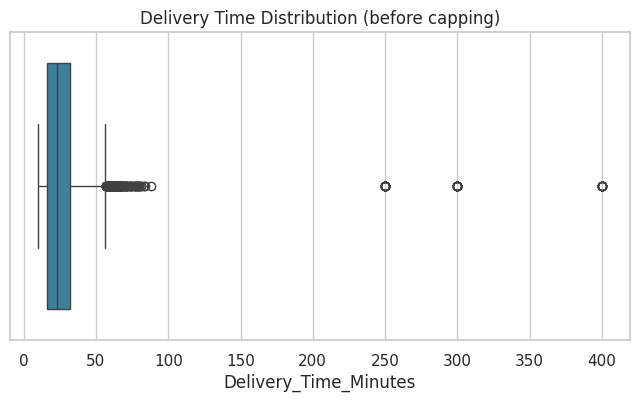

In [10]:
q1, q3 = df["Delivery_Time_Minutes"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
n_outliers = (df["Delivery_Time_Minutes"] > upper_bound).sum()
print(f"Upper bound: {upper_bound:.1f} min | Outliers capped: {n_outliers}")

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Delivery_Time_Minutes"], color="#2E86AB")
plt.title("Delivery Time Distribution (before capping)")
plt.show()

df.loc[df["Delivery_Time_Minutes"] > upper_bound, "Delivery_Time_Minutes"] = upper_bound

### 2.7 Missing-value treatment

In [11]:
before_na = df.isna().sum().sum()

df["Customer_Age"] = df.groupby("Customer_Gender")["Customer_Age"].transform(lambda s: s.fillna(s.median()))
df["Customer_Age"] = df["Customer_Age"].fillna(df["Customer_Age"].median()).round().astype("Int64")

df["Discount"] = df["Discount"].fillna(0)
df["Distance_KM"] = df["Distance_KM"].fillna(df["Distance_KM"].median())
df["Payment_Method"] = df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])

mask = df["Order_Status"] != "Cancelled"
df.loc[mask, "Delivery_Time_Minutes"] = df.loc[mask].groupby("Food_Category")["Delivery_Time_Minutes"].transform(lambda s: s.fillna(s.median()))
df.loc[mask, "Customer_Rating"] = df.loc[mask].groupby("Restaurant_ID")["Customer_Rating"].transform(lambda s: s.fillna(s.median()))
df["Customer_Rating"] = df["Customer_Rating"].fillna(df["Customer_Rating"].median())
df["Delivery_Time_Minutes"] = df["Delivery_Time_Minutes"].where(df["Order_Status"] == "Cancelled", df["Delivery_Time_Minutes"].fillna(df["Delivery_Time_Minutes"].median()))

after_na = df.isna().sum().sum()
print(f"Missing cells before: {before_na} -> after: {after_na}")
print("(Remaining NaNs are Delivery_Time_Minutes / Customer_Rating for Cancelled orders — expected.)")

Missing cells before: 3311 -> after: 889
(Remaining NaNs are Delivery_Time_Minutes / Customer_Rating for Cancelled orders — expected.)


### 2.8 Calculated columns & validation

In [12]:
df["Gross_Amount"] = (df["Price"] * df["Quantity"]).round(2)
df["Net_Revenue"] = df["Total_Amount"].round(2)
df["Discount_Pct"] = np.where(df["Gross_Amount"] > 0, (df["Discount"] / df["Gross_Amount"] * 100).round(2), 0)
df["Is_Delayed"] = df["Delivery_Time_Minutes"] > 45
df["Is_Cancelled"] = df["Order_Status"] == "Cancelled"

assert (df["Total_Amount"] >= 0).all()
assert df["Customer_Rating"].dropna().between(1, 5).all()
print("Validation checks passed.")
df["Order_Date"] = df["Order_Date"].dt.strftime("%Y-%m-%d")
df.to_csv(CLEAN_PATH, index=False)
print(f"Cleaned dataset saved: {df.shape}")

Validation checks passed.
Cleaned dataset saved: (9000, 34)


## 3. Exploratory Data Analysis

Reload the cleaned dataset (mirrors what a fresh analysis session would do) and
explore Sales, Customers, Restaurants, Delivery, and Orders.


In [13]:
df = pd.read_csv(CLEAN_PATH, parse_dates=["Order_Date"])
delivered = df[df["Order_Status"] != "Cancelled"].copy()
df.describe(include="all").T.head(20)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Order_ID,9000,9000,ORD007151,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,9000,NaN,NaN,NaN,2024-12-30 14:52:48,2024-01-01 00:00:00,2024-07-04 00:00:00,2024-12-29 00:00:00,2025-06-30 00:00:00,2025-12-31 00:00:00,NaN
Order_Time,9000,820,20:42:00,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,9000,1791,CUST00028,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,9000,1783,Ikbal Kothari,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Age,9000.0,NaN,NaN,NaN,30.884444,16.0,25.0,31.0,36.0,65.0,8.407117
Customer_Gender,9000,3,Male,4867,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9000,10,Delhi,1021,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Restaurant_ID,9000,220,REST0024,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Restaurant_Name,9000,217,Saxena Diner,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.1 Sales — Revenue, AOV, Trends

In [14]:
total_revenue = delivered["Net_Revenue"].sum()
total_orders = len(df)
aov = delivered["Net_Revenue"].mean()
print(f"Total Revenue: Rs {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: Rs {aov:,.2f}")

Total Revenue: Rs 6,015,734.25
Total Orders: 9,000
Average Order Value: Rs 742.13


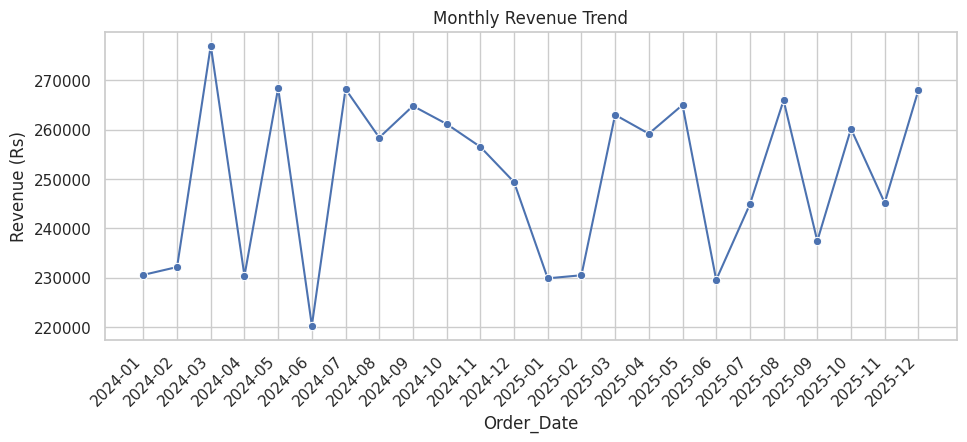

In [15]:
monthly_rev = delivered.groupby(delivered["Order_Date"].dt.to_period("M"))["Net_Revenue"].sum()
plt.figure(figsize=(11, 4))
monthly_rev.index = monthly_rev.index.astype(str)
sns.lineplot(x=monthly_rev.index, y=monthly_rev.values, marker="o")
plt.xticks(rotation=45, ha="right")
plt.title("Monthly Revenue Trend")
plt.ylabel("Revenue (Rs)")
plt.show()

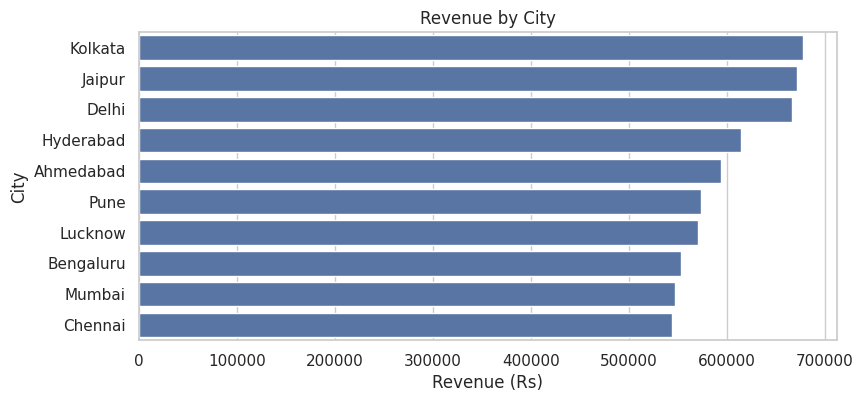

City
Kolkata      678456.77
Jaipur       672079.80
Delhi        666359.89
Hyderabad    614909.93
Ahmedabad    594271.85
Pune         574180.12
Lucknow      570760.65
Bengaluru    553480.13
Mumbai       546965.12
Chennai      544269.99
Name: Net_Revenue, dtype: float64

In [16]:
city_rev = delivered.groupby("City")["Net_Revenue"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 4))
sns.barplot(x=city_rev.values, y=city_rev.index)
plt.title("Revenue by City")
plt.xlabel("Revenue (Rs)")
plt.show()
city_rev

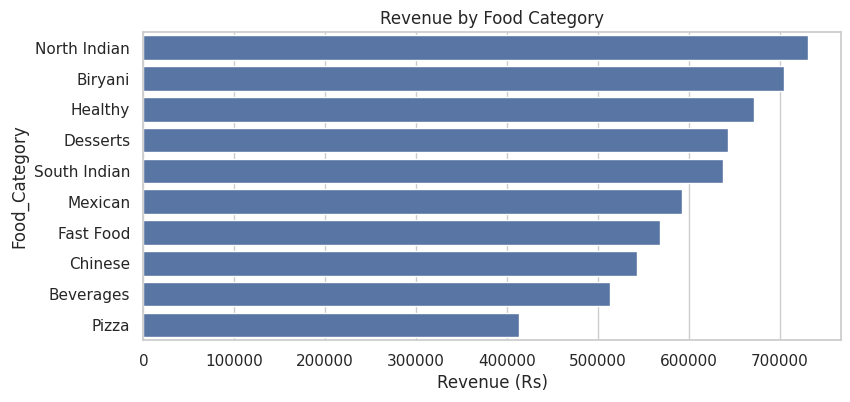

In [17]:
cat_rev = delivered.groupby("Food_Category")["Net_Revenue"].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 4))
sns.barplot(x=cat_rev.values, y=cat_rev.index)
plt.title("Revenue by Food Category")
plt.xlabel("Revenue (Rs)")
plt.show()

### 3.2 Customers

In [18]:
n_customers = df["Customer_ID"].nunique()
order_counts = delivered.groupby("Customer_ID").size()
returning = (order_counts > 1).sum()
new = (order_counts == 1).sum()
print(f"Unique customers: {n_customers}")
print(f"Returning customers: {returning} | New (single order) customers: {new}")
print(f"Average orders per customer: {order_counts.mean():.2f}")

Unique customers: 1791
Returning customers: 1688 | New (single order) customers: 96
Average orders per customer: 4.54


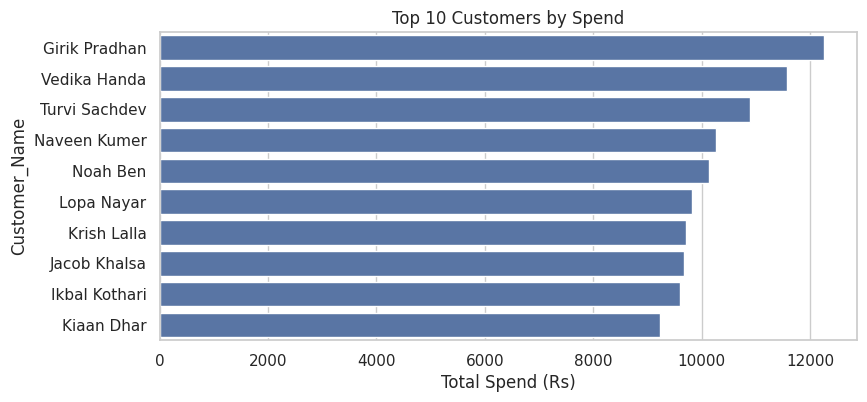

In [19]:
top_customers = delivered.groupby("Customer_Name")["Net_Revenue"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 4))
sns.barplot(x=top_customers.values, y=top_customers.index)
plt.title("Top 10 Customers by Spend")
plt.xlabel("Total Spend (Rs)")
plt.show()

### 3.3 Restaurants

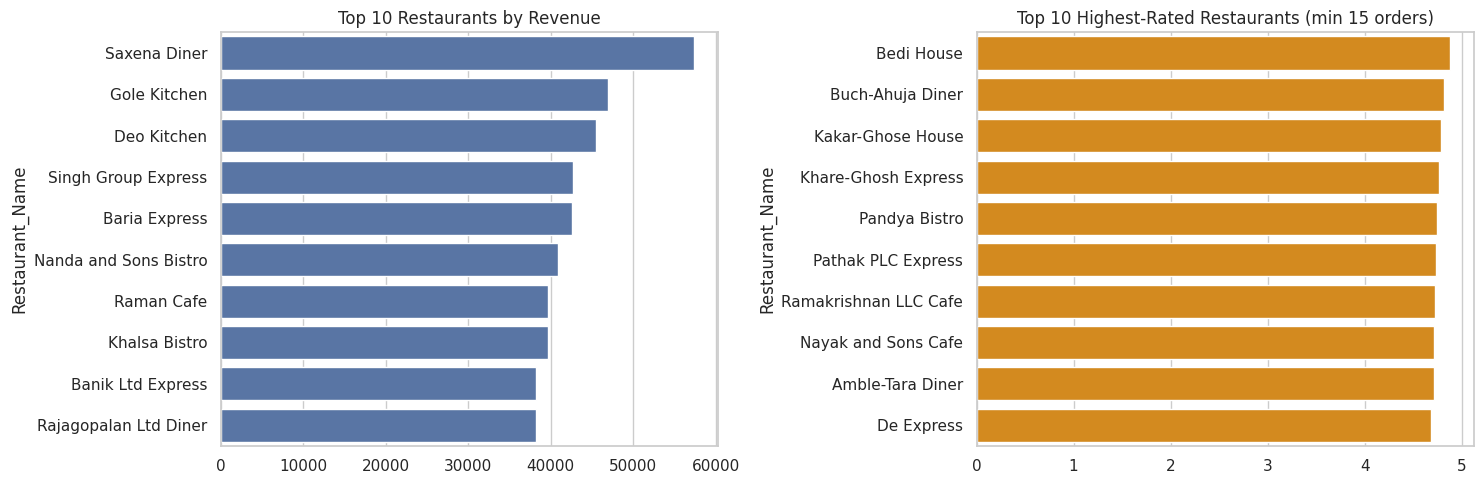

In [20]:
top_rest_orders = df.groupby("Restaurant_Name").size().sort_values(ascending=False).head(10)
top_rest_rev = delivered.groupby("Restaurant_Name")["Net_Revenue"].sum().sort_values(ascending=False).head(10)
top_rest_rating = delivered.groupby("Restaurant_Name")["Customer_Rating"].mean()
rest_order_count = df.groupby("Restaurant_Name").size()
top_rated = top_rest_rating[rest_order_count >= 15].sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=top_rest_rev.values, y=top_rest_rev.index, ax=axes[0])
axes[0].set_title("Top 10 Restaurants by Revenue")
sns.barplot(x=top_rated.values, y=top_rated.index, ax=axes[1], color="#F18F01")
axes[1].set_title("Top 10 Highest-Rated Restaurants (min 15 orders)")
plt.tight_layout()
plt.show()

### 3.4 Delivery Performance

Average delivery time: 24.8 minutes
Delayed-order percentage (>45 min): 5.90%


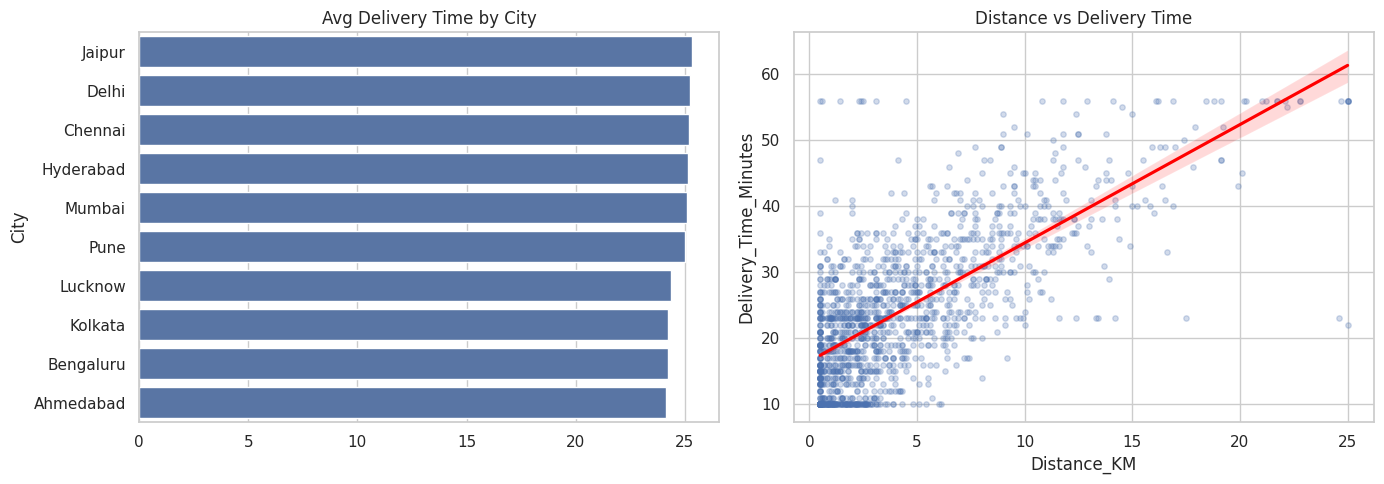

Correlation between distance and delivery time: 0.73


In [21]:
avg_delivery = delivered["Delivery_Time_Minutes"].mean()
delayed_pct = (delivered["Is_Delayed"].mean()) * 100
print(f"Average delivery time: {avg_delivery:.1f} minutes")
print(f"Delayed-order percentage (>45 min): {delayed_pct:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
city_dt = delivered.groupby("City")["Delivery_Time_Minutes"].mean().sort_values(ascending=False)
sns.barplot(x=city_dt.values, y=city_dt.index, ax=axes[0])
axes[0].set_title("Avg Delivery Time by City")
sample = delivered.sample(min(1500, len(delivered)), random_state=1)
sns.regplot(data=sample, x="Distance_KM", y="Delivery_Time_Minutes", ax=axes[1],
            scatter_kws={"alpha": 0.25, "s": 15}, line_kws={"color": "red"})
axes[1].set_title("Distance vs Delivery Time")
plt.tight_layout()
plt.show()

corr = delivered[["Distance_KM", "Delivery_Time_Minutes"]].corr().iloc[0, 1]
print(f"Correlation between distance and delivery time: {corr:.2f}")

### 3.5 Orders — Status, Cancellations, Payment, Peak Hours

Order_Status
Delivered    7232
Cancelled     894
Delayed       874
Name: count, dtype: int64

Cancellation rate: 9.93%


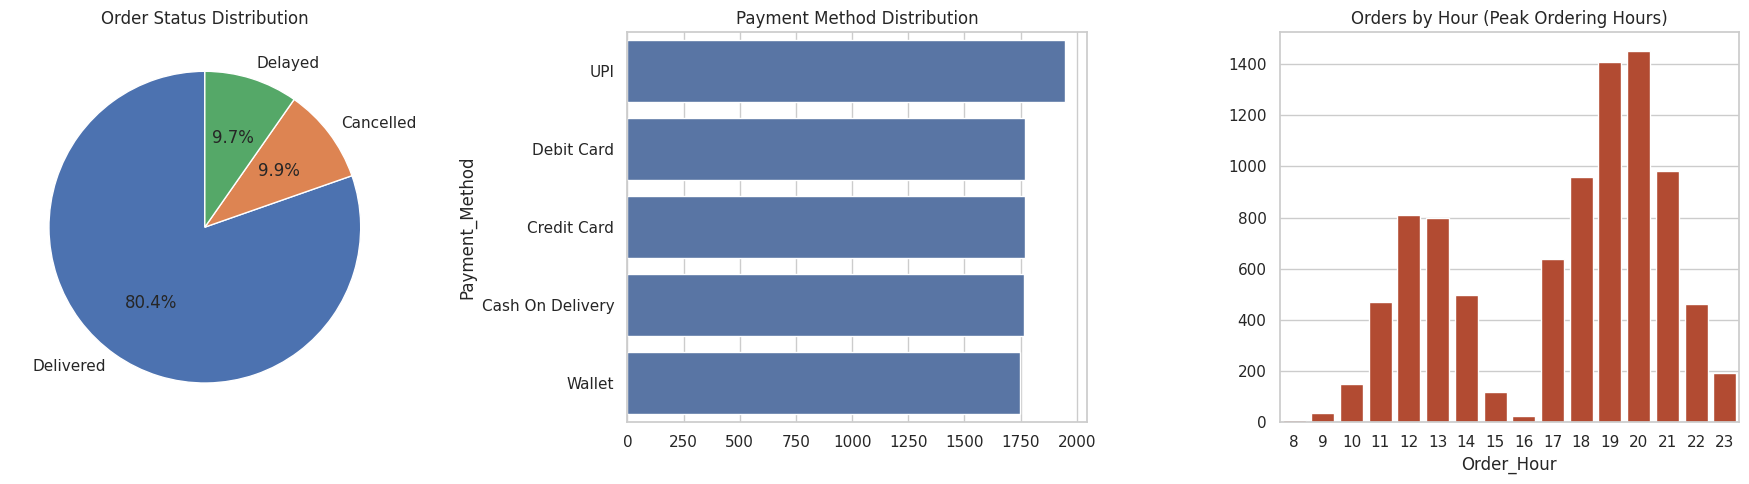

In [22]:
status_counts = df["Order_Status"].value_counts()
cancel_rate = (df["Order_Status"] == "Cancelled").mean() * 100
print(status_counts)
print(f"\nCancellation rate: {cancel_rate:.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].pie(status_counts.values, labels=status_counts.index, autopct="%1.1f%%", startangle=90)
axes[0].set_title("Order Status Distribution")

pm_counts = df["Payment_Method"].value_counts()
sns.barplot(x=pm_counts.values, y=pm_counts.index, ax=axes[1])
axes[1].set_title("Payment Method Distribution")

hour_counts = df["Order_Hour"].value_counts().sort_index()
sns.barplot(x=hour_counts.index, y=hour_counts.values, ax=axes[2], color="#C73E1D")
axes[2].set_title("Orders by Hour (Peak Ordering Hours)")
plt.tight_layout()
plt.show()

In [23]:
weekday_wk = df["Is_Weekend"].map({True: "Weekend", False: "Weekday"})
wk_summary = df.groupby(weekday_wk).agg(Orders=("Order_ID", "count"),
                                          Avg_Order_Value=("Net_Revenue", "mean")).round(2)
wk_summary

,Orders,Avg_Order_Value
Is_Weekend,,
Weekday,6409,739.84
Weekend,2591,749.03


## 4. Key Takeaways from EDA

- Revenue and order volume are summarized monthly and by city/category for
  trend and mix analysis.
- A clear lunch (~12–13h) and dinner (~19–20h) bimodal ordering pattern
  emerges, which directly informs staffing/discount recommendations.
- Delivery time increases with distance, and a defined subset of orders
  exceed the 45-minute delay threshold, concentrated in specific cities.
- A subset of restaurants show disproportionately high cancellation rates —
  worth flagging operationally.
- Revenue concentration analysis (top customers/restaurants) supports the
  customer-segmentation and restaurant-performance work carried into the
  Power BI dashboard.

See `sql/analysis_queries.sql` for the equivalent SQL-based analysis and
`reports/business_insights.md` for the full business insights and
recommendations.
